# 03 – Kiểm tra chất lượng dữ liệu sinh (AI-3)
Trả lời các câu hỏi trong đề bài: giá trị có hợp lệ không, phân phối có gần dữ liệu thật không, lớp hiếm có được sinh đủ không,
có nhiều bản ghi trùng hoặc quá giống dữ liệu huấn luyện không.

Cần có sẵn file dữ liệu sinh trong `outputs/` (từ notebook 02 và/hoặc 03). Notebook tự dùng các file tìm thấy.

**Lưu ý:** đây là kiểm tra sơ bộ của nhóm AI. Tập tham chiếu "thật chưa dùng huấn luyện" ở đây là file testing của UNSW-NB15; khi nhóm Data Science chốt
quy tắc chia dữ liệu (DS2) phải thay bằng holdout chính thức.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import config, data

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

DATASET = "unsw_nb15"   # đổi thành "cicids2017" để chạy dataset kia

from src.ctgan_pipeline import quick_fidelity
from src import evaluation as ev

CAP_PER_CLASS = 3000   # PHẢI bằng giá trị đã dùng khi huấn luyện (500 nếu bạn chạy SMOKE_TEST)


## 1. Dữ liệu thật và dữ liệu sinh

In [2]:
train, test = data.load(DATASET)
real, LABEL, DISCRETE = data.prepare_for_ctgan(train, DATASET, cap_per_class=CAP_PER_CLASS)
holdout = data.prepare_test(test, DATASET, real.columns)
print("Huấn luyện:", real.shape, "| Tham chiếu thật (chưa dùng huấn luyện):", holdout.shape)

synths = {}
for name, fname in {"CTGAN": f"synthetic_ctgan_{DATASET}.csv", "TVAE": f"synthetic_tvae_{DATASET}.csv"}.items():
    f = config.OUT_DIR / fname
    if f.exists():
        synths[name] = pd.read_csv(f)
        print(f"{name}: {synths[name].shape}")
    else:
        print(f"{name}: chưa có file {fname}, bỏ qua")

Huấn luyện: (23009, 53) | Tham chiếu thật (chưa dùng huấn luyện): (82332, 53)
CTGAN: (18886, 53)
TVAE: chưa có file synthetic_tvae_unsw_nb15.csv, bỏ qua


## 2. Số bản ghi từng lớp: thật so với sinh
Cột `sinh/thật` gần 1 là tốt. Lớp hiếm có tỷ lệ thấp nghĩa là mô hình sinh không đủ lớp đó.

In [3]:
for name, s in synths.items():
    print(f"=== {name} ===")
    display(ev.class_table(real, s, LABEL))

=== CTGAN ===


,thật,sinh,sinh/thật
attack_cat,,,
Worms,130,886,6.82
Shellcode,1133,2000,1.77
Backdoor,1746,2000,1.15
Analysis,2000,2000,1.00
Fuzzers,3000,2000,0.67
Generic,3000,2000,0.67
DoS,3000,2000,0.67
Exploits,3000,2000,0.67
Reconnaissance,3000,2000,0.67


## 3. Hợp lệ và độ giống phân phối
`invalid_share` là tỷ lệ dòng có giá trị ngoài khoảng dữ liệu thật (cột số) hoặc giá trị chưa từng thấy (cột rời rạc). `distance` là KS (cột số) hoặc total variation (cột rời rạc), càng gần 0 càng giống.

In [4]:
for name, s in synths.items():
    print(f"=== {name} ===")
    v = ev.validity_report(real, s, DISCRETE)
    print("Số cột có dòng không hợp lệ:", int((v["invalid_share"] > 0).sum()), "/", len(v))
    display(v.head(8))
    fid = quick_fidelity(real, s, DISCRETE)
    print("Khoảng cách trung bình:", round(fid["distance"].mean(), 3))
    display(fid.head(8))

=== CTGAN ===
Số cột có dòng không hợp lệ: 31 / 53


,column,type,invalid_share
0,response_body_len,numeric,0.740178
1,dtcpb,numeric,0.598539
2,dinpkt,numeric,0.498994
3,log_dbytes,numeric,0.413640
4,ackdat,numeric,0.378746
5,log_dinpkt,numeric,0.369745
6,dur,numeric,0.368209
7,stcpb,numeric,0.331251


Khoảng cách trung bình: 0.242


,column,type,distance
0,response_body_len,numeric,0.740178
1,dtcpb,numeric,0.598539
2,tcprtt,numeric,0.520206
3,dbytes,numeric,0.517910
4,dinpkt,numeric,0.498994
5,sinpkt,numeric,0.465302
6,dmean,numeric,0.462688
7,sbytes,numeric,0.456816


### Dòng không hợp lệ và hậu xử lý
`invalid_rows` là tỷ lệ dòng có **ít nhất một** giá trị không thể có (ví dụ số gói tin âm). `clip_to_real_range` kéo các cột số về khoảng của dữ liệu thật. Đây là hậu xử lý, báo cáo kết quả cả hai trường hợp.

In [5]:
rows = {}
for name, s in synths.items():
    fixed = ev.clip_to_real_range(real, s, DISCRETE)
    rows[name] = {"invalid_rows_raw": ev.invalid_row_share(real, s, DISCRETE),
                  "invalid_rows_after_clip": ev.invalid_row_share(real, fixed, DISCRETE)}
pd.DataFrame(rows).round(4)

,CTGAN
invalid_rows_raw,0.9748
invalid_rows_after_clip,0.0000


## 4. Bản ghi trùng / sao chép dữ liệu huấn luyện

In [6]:
dups = pd.DataFrame({name: ev.duplicate_report(real, s, DISCRETE) for name, s in synths.items()})
dups

,CTGAN
synth_copy_of_train_share,0.000000
synth_internal_duplicate_share,0.000000
train_internal_duplicate_share,0.193403


## 5. Khoảng cách tới bản ghi huấn luyện gần nhất (DCR)
Mỗi dòng sinh ra được đo khoảng cách tới dòng huấn luyện gần nhất. Tham chiếu là khoảng cách từ các dòng thật **chưa dùng huấn luyện** tới tập huấn luyện.
Nếu dòng sinh ra gần tập huấn luyện hơn hẳn tập tham chiếu (`share_closer_than_holdout_p5` lớn hơn nhiều so với 0.05) thì có dấu hiệu mô hình nhớ dữ liệu.
DCR là chỉ báo sơ bộ về rò rỉ, **không thay thế** MIA của nhóm Cyber Security.

=== CTGAN ===


,synthetic,real_holdout
median_dcr,6.272520,0.775312
p5_dcr,4.381972,0.046016
min_dcr,2.367162,0.000000
share_exact_match,0.000000,0.028400
share_closer_than_holdout_p5,0.000000,0.050000


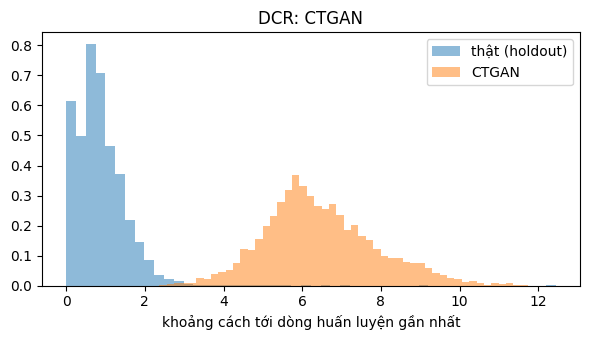

In [7]:
fig, axes = plt.subplots(1, max(len(synths), 1), figsize=(6 * max(len(synths), 1), 3.5), squeeze=False)
for ax, (name, s) in zip(axes[0], synths.items()):
    summary, d_sy, d_ho = ev.dcr_report(real, s, holdout, DISCRETE)
    print(f"=== {name} ===")
    display(summary)
    ax.hist(d_ho, bins=50, alpha=0.5, label="thật (holdout)", density=True)
    ax.hist(d_sy, bins=50, alpha=0.5, label=name, density=True)
    ax.set_title(f"DCR: {name}"); ax.set_xlabel("khoảng cách tới dòng huấn luyện gần nhất"); ax.legend()
plt.tight_layout(); plt.show()

## Cách đọc kết quả
- Lớp hiếm có `sinh/thật` thấp: mô hình không biểu diễn được lớp đó (ghi vào phần phát hiện nghiên cứu).
- `share_exact_match` > 0 hoặc `synth_copy_of_train_share` cao: mô hình sao chép bản ghi huấn luyện.
- Hai mô hình khác nhau thế nào? Ghi lại để trả lời câu hỏi AI Research 2 (TVAE so với CTGAN).